# AIMLCZG521 — Conversational AI
### Assignment 1 - PS2 - Hybrid Retrieval for Financial Conversational Question Answering
**Group:** 61
| Sr. No. | Name | ID |
| :---: | :--- | :---: |
| 1 | MAYUR INGLE | 2024ac05106 |
| 2 | BARHATE LOKESHWAR BHAGWAT | 2024ac05004 |
| 3 | MOHIT PUNDLIK HEDAOO | 2024ac05565 |
| 4 | PALLAVI VERMA | 2024ac05016 |


**Problem Statement 2** — Build a Financial Domain Hybrid Search QA System combining sparse (BM25/TF-IDF) and dense (embeddings) retrieval to answer finance-related queries.

**Dataset:** FiQA-2018 (Financial Intelligence over Questions and Answers)  
**Source:** https://huggingface.co/datasets/pauri32/fiqa-2018

The system covers the full pipeline — data cleaning, sparse retrieval, semantic retrieval, hybrid fusion using RRF, a conversational QA interface, and evaluation using standard IR metrics.

In [15]:
# installing all required libraries
# rank_bm25 for sparse retrieval, faiss for vector indexing, sentence-transformers for embeddings
# datasets to load fiqa from huggingface, nltk for text preprocessing

!pip install rank_bm25 faiss-cpu sentence-transformers datasets nltk -q

In [16]:
import re
import string
import numpy as np
import pandas as pd
import nltk
import warnings
warnings.filterwarnings('ignore')

from datasets import load_dataset
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics.pairwise import cosine_similarity
import faiss
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import defaultdict
import time

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

print("all imports done")

all imports done


## Module 1: Data Preparation & Sparse Retrieval

### Task 1 — Data Cleaning and Preparation

We're using FiQA-2018 (BEIR version) — a financial QA dataset from Stack Exchange and Reddit finance threads. It has three parts: a corpus of passages, a set of questions, and qrels (relevance judgments that tell us which passage answers which question).

Before indexing anything, we need to clean the raw text. Financial text is quite noisy — there are URLs, HTML leftovers, ticker symbols like $TSLA, abbreviations like P/E and CAGR, and inconsistent casing. All of this can hurt both BM25 (bad tokenization) and embeddings (noisy input).

In [17]:
# pauri32/fiqa-2018 turned out to be the sentiment split, not the retrieval split
# using the correct BEIR version of FiQA which has corpus, queries and qrels
# BEIR (Benchmarking IR) is the standard benchmark used in retrieval research

print("loading FiQA retrieval dataset from BEIR...")
dataset = load_dataset("BeIR/fiqa", "corpus")
print(dataset)
print("\nfirst corpus entry:")
print(dataset['corpus'][0])

# loading queries separately
queries_dataset = load_dataset("BeIR/fiqa", "queries")
print(queries_dataset)
print("\nfirst query:")
print(queries_dataset['queries'][0])

# loading the qrels (relevance judgments) - needed for evaluation later
# qrels tell us which corpus doc is the correct answer for each query
qrels_dataset = load_dataset("BeIR/fiqa-qrels")
print(qrels_dataset)
print("\nfirst qrel entry:")
print(qrels_dataset['train'][0])

loading FiQA retrieval dataset from BEIR...
DatasetDict({
    corpus: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 57638
    })
})

first corpus entry:
{'_id': '3', 'title': '', 'text': "I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems in the U.S. (or their students) should worry a little about getting marketable skills in exchange for their massive investment in education, rather than getting out with thousands in student debt and then complaining that they aren't qualified to do anything."}
DatasetDict({
    queries: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 6648
    })
})

first query:
{'_id': '0', 'title': '', 'text': 'What is considered a business expense on a business trip?'}
DatasetDict({
    train: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num

In [18]:
# converting all three to dataframes and doing a quick sanity check

corpus_df = pd.DataFrame(dataset['corpus'])
queries_df = pd.DataFrame(queries_dataset['queries'])
qrels_df = pd.DataFrame(qrels_dataset['train'])  # using train qrels for evaluation

print("corpus shape:", corpus_df.shape)
print("queries shape:", queries_df.shape)
print("qrels shape:", qrels_df.shape)

print("\ncorpus columns:", corpus_df.columns.tolist())
print("queries columns:", queries_df.columns.tolist())
print("qrels columns:", qrels_df.columns.tolist())

print("\ncorpus sample:")
print(corpus_df.head(2))

print("\nqueries sample:")
print(queries_df.head(2))

print("\nqrels sample:")
print(qrels_df.head(3))

corpus shape: (57638, 3)
queries shape: (6648, 3)
qrels shape: (14166, 3)

corpus columns: ['_id', 'title', 'text']
queries columns: ['_id', 'title', 'text']
qrels columns: ['query-id', 'corpus-id', 'score']

corpus sample:
  _id title                                               text
0   3        I'm not saying I don't like the idea of on-the...
1  31        So nothing preventing false ratings besides ad...

queries sample:
  _id title                                               text
0   0        What is considered a business expense on a bus...
1   4        Business Expense - Car Insurance Deductible Fo...

qrels sample:
   query-id  corpus-id  score
0         0      18850      1
1         4     196463      1
2         5      69306      1


In [19]:
# --- preprocessing pipeline ---
# keeping it practical - finance text has $ signs, % symbols, abbreviations
# we clean noise but don't destroy domain-specific tokens

stop_words = set(stopwords.words('english'))

def clean_text(text):
    if not isinstance(text, str) or text.strip() == '':
        return ''

    # remove html tags if any
    text = re.sub(r'<[^>]+>', ' ', text)

    # remove urls
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # lowercase
    text = text.lower()

    # remove special chars except alphanumeric, spaces, and basic punctuation
    # keeping % and . because "10%" and "p.e ratio" matter in finance
    text = re.sub(r'[^a-z0-9\s\.\%]', ' ', text)

    # normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def tokenize_for_bm25(text):
    # simple whitespace tokenize after cleaning, remove stopwords
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    return tokens

# apply cleaning to corpus
print("cleaning corpus...")
corpus_df['clean_text'] = corpus_df['text'].apply(clean_text)

# combine title + text where title is available (some entries have empty title)
corpus_df['full_text'] = corpus_df.apply(
    lambda row: (row['title'] + ' ' + row['text']).strip() if row['title'] else row['text'],
    axis=1
)
corpus_df['clean_full_text'] = corpus_df['full_text'].apply(clean_text)

# tokenize for bm25
corpus_df['tokens'] = corpus_df['clean_full_text'].apply(tokenize_for_bm25)

# filter out empty docs
before = len(corpus_df)
corpus_df = corpus_df[corpus_df['tokens'].apply(len) > 3].reset_index(drop=True)
after = len(corpus_df)

print(f"removed {before - after} near-empty documents")
print(f"final corpus size: {after}")
print("\nsample cleaned entry:")
print("original:", corpus_df['text'][0][:200])
print("\ncleaned:", corpus_df['clean_full_text'][0][:200])
print("\ntokens (first 15):", corpus_df['tokens'][0][:15])

cleaning corpus...
removed 123 near-empty documents
final corpus size: 57515

sample cleaned entry:
original: I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems

cleaned: i m not saying i don t like the idea of on the job training too but you can t expect the company to do that. training workers is not their job they re building software. perhaps educational systems in

tokens (first 15): ['saying', 'like', 'idea', 'job', 'training', 'expect', 'company', 'that.', 'training', 'workers', 'job', 'building', 'software.', 'perhaps', 'educational']


In [20]:
# quick stats on the cleaned corpus - good to report in analysis

token_lengths = corpus_df['tokens'].apply(len)
print("token length stats (per document):")
print(f"  mean:   {token_lengths.mean():.1f}")
print(f"  median: {token_lengths.median():.1f}")
print(f"  min:    {token_lengths.min()}")
print(f"  max:    {token_lengths.max()}")

# also clean queries
queries_df['clean_query'] = queries_df['text'].apply(clean_text)
queries_df['query_tokens'] = queries_df['clean_query'].apply(tokenize_for_bm25)

print(f"\ntotal queries: {len(queries_df)}")
print("\nsample cleaned query:")
print("original:", queries_df['text'][0])
print("cleaned: ", queries_df['clean_query'][0])

token length stats (per document):
  mean:   69.1
  median: 47.0
  min:    4
  max:    1534

total queries: 6648

sample cleaned query:
original: What is considered a business expense on a business trip?
cleaned:  what is considered a business expense on a business trip


#### Task 1 Analysis

Preprocessing matters here more than in typical NLP tasks because financial text mixes formal writing with community forum noise. Some specific issues we ran into:

- Ticker symbols like $LNG or $AAPL get split weirdly by standard tokenizers after punctuation removal
- Abbreviations like NAV, SIP, CAGR are critical domain terms but look like noise to general pipelines
- Numbers and percentages ("10%", "10 %", "ten percent") represent the same thing but appear as different tokens
- Words like "yield", "hedge", "spread" mean something completely different in finance vs general English — pretrained models can get confused

We decided to keep percentage signs and dots during cleaning since "10%" and "P.E" carry meaning, but strip everything else noisy. Stopword removal helps reduce noise but we were careful not to remove finance-relevant short tokens.

## Task 2 — Sparse Search System (BM25)

BM25 (Best Match 25) is the industry standard for keyword-based retrieval. It improves over TF-IDF by adding two things:
- **Term frequency saturation** — repeated terms don't keep adding score linearly, they plateau
- **Document length normalization** — longer documents don't get unfair advantage

BM25 formula for a query Q and document D:

$$Score(D, Q) = \sum_{i=1}^{n} IDF(q_i) \cdot \frac{f(q_i, D) \cdot (k_1 + 1)}{f(q_i, D) + k_1 \cdot (1 - b + b \cdot \frac{|D|}{avgdl})}$$

where k1 controls term frequency saturation (typically 1.2–2.0) and b controls length normalization (typically 0.75).

We build a BM25 index over the entire FiQA corpus and retrieve Top-K passages for financial queries.

In [21]:
# building the BM25 index over cleaned+tokenized corpus
# BM25Okapi is the standard okapi BM25 implementation in rank_bm25

print("building BM25 index...")
start = time.time()

bm25 = BM25Okapi(corpus_df['tokens'].tolist())

elapsed = time.time() - start
print(f"BM25 index built in {elapsed:.2f}s")
print(f"indexed {len(corpus_df)} documents")
print(f"vocabulary size: {len(bm25.idf)}")

building BM25 index...
BM25 index built in 1.82s
indexed 57515 documents
vocabulary size: 95265


In [22]:
# BM25 retrieval function
# takes a raw query string, returns top-k (doc_id, score) pairs

def bm25_retrieve(query, top_k=10):
    tokens = tokenize_for_bm25(clean_text(query))
    scores = bm25.get_scores(tokens)

    # get top-k indices sorted by score descending
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []
    for idx in top_indices:
        results.append({
            'doc_id': corpus_df.iloc[idx]['_id'],
            'score': scores[idx],
            'text': corpus_df.iloc[idx]['text'][:300]  # preview
        })
    return results

# test with a sample finance query
test_query = "What is the difference between CAGR and ROI?"
print(f"query: {test_query}")
print("="*60)

results = bm25_retrieve(test_query, top_k=5)
for i, r in enumerate(results):
    print(f"\nRank {i+1} | doc_id: {r['doc_id']} | score: {r['score']:.4f}")
    print(f"text: {r['text']}...")

query: What is the difference between CAGR and ROI?

Rank 1 | doc_id: 178501 | score: 16.1895
text: I would not claim to be a personal expert in rental property. I do have friends and family and acquaintances who run rental units for additional income and/or make a full time living at the rental business.  As JoeTaxpayer points out, rentals are a cash-eating business. You need to have enough liqui...

Rank 2 | doc_id: 181013 | score: 12.3887
text: See the Moneychimp site. From 1934 to 2006, the S&P returned an 'average' 12.81%. But the CAGR was 11.26%.  I wrote an article Average Return vs Compound Annual Growth to address this issue.  Interesting that over time only a few funds have managed to get anywhere near this return, but the low cost ...

Rank 3 | doc_id: 12351 | score: 11.8269
text: I wrote a detailed article on Tax Loss Harvesting to show the impact on returns.  For my example, I showed a person in the 15% bracket. In years with no loss, they trade to capture gains at 0% long

In [23]:
# testing with a few more finance queries to see how BM25 behaves

test_queries = [
    "How does inflation affect stock markets?",
    "What are the risks of mutual fund investments?",
    "How to calculate compound interest?",
    "What is dollar cost averaging?"
]

for q in test_queries:
    print(f"\nQuery: {q}")
    print("-" * 50)
    res = bm25_retrieve(q, top_k=3)
    for i, r in enumerate(res):
        print(f"  Rank {i+1} [score: {r['score']:.3f}]: {r['text'][:150]}...")


Query: How does inflation affect stock markets?
--------------------------------------------------
  Rank 1 [score: 15.615]: "Inflation as defined in the general, has many impacts at a personal level. For example, you say that the reduction in the price of oil has no impact ...
  Rank 2 [score: 15.162]: The relation between inflation and stock (or economic) performance is not well-understood.  Decades ago, economists thought inflation corresponded wit...
  Rank 3 [score: 14.840]: The principle behind the advice to not throw good money after bad is better restated in economics terms: sunk costs are sunk and irrelevant to today's...

Query: What are the risks of mutual fund investments?
--------------------------------------------------
  Rank 1 [score: 18.163]: "Your ""money market"" is cash or a ""sweep account"" that your broker is holding for you and on which the broker is paying you interest.  The mutual ...
  Rank 2 [score: 16.947]: The main difference between an ETF and a Mutual 

In [24]:
# let's also check what happens with a finance-specific abbreviation query
# this is where BM25 either shines (exact match) or fails (vocabulary mismatch)

abbrev_queries = [
    "What is NAV in mutual funds?",       # NAV = Net Asset Value, exact term match - BM25 should do well
    "Explain P/E ratio for stock valuation",  # P/E might get split weirdly after cleaning
    "risks in SIP investment"             # SIP = Systematic Investment Plan
]

print("testing abbreviation/domain-term queries:")
print("(these expose BM25 vocabulary mismatch issues)\n")

for q in abbrev_queries:
    res = bm25_retrieve(q, top_k=1)
    print(f"Query: {q}")
    if res and res[0]['score'] > 0:
        print(f"  top result score: {res[0]['score']:.4f}")
        print(f"  preview: {res[0]['text'][:200]}...")
    else:
        print("  no relevant match found (score = 0) — vocabulary mismatch!")
    print()

testing abbreviation/domain-term queries:
(these expose BM25 vocabulary mismatch issues)

Query: What is NAV in mutual funds?
  top result score: 21.2460
  preview: This idea does not make sense for most mutual funds. The net asset value, or NAV, is the current market value of a fund's holdings, minus the fund's liabilities, that is usually expressed as a per-sha...

Query: Explain P/E ratio for stock valuation
  top result score: 19.0852
  preview: "To perhaps better explain the ""why"" behind this rule of thumb, first think of what it means when the P/E ratio changes.  If the P/E ratio increases, then this means the stock has become more expens...

Query: risks in SIP investment
  top result score: 14.5528
  preview: "Yes, the ""speed bump"" explicitly can not impact the reports to the SIP. Two years ago this would not be a big deal, because the SIP was stupidly slow, especially under load. So, you send your repor...



#### Task 2 Analysis

BM25 works really well when the query uses the exact same words as the document. For finance queries with specific terms like "CAGR", "NAV", or "401k", it picks up matches reliably and is extremely fast.

The problem shows up with paraphrased queries. If someone asks "how do I grow my savings over time", BM25 scores near zero for a document that talks about "compound interest and long-term returns" — no shared tokens, no match. This vocabulary mismatch is the core limitation.

After cleaning, abbreviations like "P/E" become "p e" (two tokens), which further reduces matching precision. Overall BM25 is a strong baseline for keyword-heavy queries but clearly needs semantic support for the kind of natural language questions users actually ask.

## Module 2: Embeddings & Hybrid Retrieval

### Task 3 — Semantic Retrieval using Sentence Embeddings

Unlike BM25 which matches exact keywords, dense retrieval converts text into dense vector representations (embeddings) where semantically similar texts are close to each other in vector space.

For example — "how do I grow my savings" and "compound interest strategies" will have high cosine similarity even though they share zero words.

We experiment with two embedding models as required:
- **Model 1:** `all-MiniLM-L6-v2` — lightweight, fast, general purpose (22M params)
- **Model 2:** `BAAI/bge-small-en-v1.5` — stronger retrieval-tuned model, trained with contrastive learning specifically for passage retrieval

We also compare two similarity metrics:
- **Cosine similarity** — measures angle between vectors, scale-invariant
- **Dot product** — faster, but sensitive to vector magnitude

Embeddings are stored in a FAISS index for efficient similarity search.

In [25]:
# loading both embedding models
# MiniLM is fast and good for general use
# BGE (BAAI General Embeddings) is specifically tuned for retrieval tasks

print("loading embedding models...")

model_minilm = SentenceTransformer('all-MiniLM-L6-v2')
print("model 1 loaded: all-MiniLM-L6-v2")

model_bge = SentenceTransformer('BAAI/bge-small-en-v1.5')
print("model 2 loaded: BAAI/bge-small-en-v1.5")

print("\nmodel 1 embedding dim:", model_minilm.get_sentence_embedding_dimension())
print("model 2 embedding dim:", model_bge.get_sentence_embedding_dimension())

loading embedding models...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

model 2 loaded: BAAI/bge-small-en-v1.5

model 1 embedding dim: 384
model 2 embedding dim: 384


In [27]:
# 57k documents is too large for Colab CPU encoding
# using a random sample of 5000 documents — enough for a meaningful retrieval demo
# sampling with a fixed seed for reproducibility

SAMPLE_SIZE = 5000
corpus_sample = corpus_df.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
corpus_texts = corpus_sample['clean_full_text'].tolist()

print(f"using {SAMPLE_SIZE} sampled documents from corpus (random_state=42)")
print(f"this keeps encoding time manageable on Colab\n")

# model 1 - MiniLM
print("encoding with MiniLM...")
start = time.time()
embeddings_minilm = model_minilm.encode(
    corpus_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
t1 = time.time() - start
print(f"MiniLM done in {t1:.1f}s | shape: {embeddings_minilm.shape}")

# model 2 - BGE
print("\nencoding with BGE...")
corpus_texts_bge = ["Represent this sentence for retrieval: " + t for t in corpus_texts]
start = time.time()
embeddings_bge = model_bge.encode(
    corpus_texts_bge,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
t2 = time.time() - start
print(f"BGE done in {t2:.1f}s | shape: {embeddings_bge.shape}")

using 5000 sampled documents from corpus (random_state=42)
this keeps encoding time manageable on Colab

encoding with MiniLM...


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

MiniLM done in 364.6s | shape: (5000, 384)

encoding with BGE...


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

BGE done in 966.5s | shape: (5000, 384)


In [30]:
# building FAISS indexes for both models
# instead of re-encoding for dot product, we derive raw embeddings mathematically
# normalized_vec = vec / ||vec||, so raw_vec = normalized_vec * ||vec||
# but for comparison purposes, we can just use a copy with different index type

dim_minilm = embeddings_minilm.shape[1]
dim_bge = embeddings_bge.shape[1]

# cosine similarity index (inner product on normalized vectors = cosine sim)
index_minilm_cos = faiss.IndexFlatIP(dim_minilm)
index_minilm_cos.add(embeddings_minilm.astype('float32'))

index_bge_cos = faiss.IndexFlatIP(dim_bge)
index_bge_cos.add(embeddings_bge.astype('float32'))

# for dot product — use L2 index on same normalized embeddings
# IndexFlatL2 uses euclidean distance, gives different ranking than cosine
# this serves as our second similarity metric comparison
index_minilm_dot = faiss.IndexFlatL2(dim_minilm)
index_minilm_dot.add(embeddings_minilm.astype('float32'))

index_bge_dot = faiss.IndexFlatL2(dim_bge)
index_bge_dot.add(embeddings_bge.astype('float32'))

print("FAISS indexes built:")
print(f"  MiniLM cosine (IP) index: {index_minilm_cos.ntotal} vectors")
print(f"  BGE cosine (IP) index:    {index_bge_cos.ntotal} vectors")
print(f"  MiniLM L2 index:          {index_minilm_dot.ntotal} vectors")
print(f"  BGE L2 index:             {index_bge_dot.ntotal} vectors")

FAISS indexes built:
  MiniLM cosine (IP) index: 5000 vectors
  BGE cosine (IP) index:    5000 vectors
  MiniLM L2 index:          5000 vectors
  BGE L2 index:             5000 vectors


In [34]:
# encode query and search FAISS index, return top-k docs
# l2 scores are negated since lower distance = more similar
def dense_retrieve(query, model, index, top_k=10, metric='cosine', is_bge=False):
    if is_bge:
        query = "Represent this sentence for retrieval: " + query

    query_emb = model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True  # always normalize query
    ).astype('float32')

    scores, indices = index.search(query_emb, top_k)

    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx == -1:
            continue
        # for L2, lower distance = more similar, so we negate for consistent ranking display
        display_score = float(-score) if metric == 'l2' else float(score)
        results.append({
            'doc_id': corpus_sample.iloc[idx]['_id'],
            'score': display_score,
            'text': corpus_sample.iloc[idx]['text'][:300],
            'corpus_idx': int(idx)
        })
    return results

In [35]:
# dense retrieval function — works with any model + index combination
# metric param controls display (cosine uses IP score, l2 uses negated distance)
# comparing cosine vs dot product similarity on same model (MiniLM)
# this demonstrates why metric choice matters

print("cosine vs dot product — same query, same model (MiniLM)")
print("="*60)

q = "How does inflation affect stock markets?"

print(f"\nQuery: {q}\n")

res_cos = dense_retrieve(q, model_minilm, index_minilm_cos, top_k=3, metric='cosine')
res_dot = dense_retrieve(q, model_minilm, index_minilm_dot, top_k=3, metric='l2')

print("cosine similarity results:")
for i, r in enumerate(res_cos):
    print(f"  Rank {i+1} | score: {r['score']:.4f} | doc_id: {r['doc_id']}")
    print(f"           {r['text'][:120]}...")

print("\ndot product results:")
for i, r in enumerate(res_dot):
    print(f"  Rank {i+1} | score: {r['score']:.4f} | doc_id: {r['doc_id']}")
    print(f"           {r['text'][:120]}...")

# check if ranking order differs
cos_ids = [r['doc_id'] for r in res_cos]
dot_ids = [r['doc_id'] for r in res_dot]
print(f"\ncosine top-3 doc_ids: {cos_ids}")
print(f"dot product top-3 doc_ids: {dot_ids}")
print(f"ranking difference: {'YES — metric matters!' if cos_ids != dot_ids else 'same ranking'}")

cosine vs dot product — same query, same model (MiniLM)

Query: How does inflation affect stock markets?

cosine similarity results:
  Rank 1 | score: 0.5432 | doc_id: 238234
           There is a thing called the consumer price index (CPI) There is a basket of goods that the people who keep the index bas...
  Rank 2 | score: 0.5326 | doc_id: 306683
           Inflation hasn't occurred because the banks aren't using the money created by the central bank buying their debt to lend...
  Rank 3 | score: 0.5325 | doc_id: 553634
           The answer would depend on the equities held. Some can weather inflation better than others (such as companies that have...

dot product results:
  Rank 1 | score: -0.9137 | doc_id: 238234
           There is a thing called the consumer price index (CPI) There is a basket of goods that the people who keep the index bas...
  Rank 2 | score: -0.9349 | doc_id: 306683
           Inflation hasn't occurred because the banks aren't using the money created by the 

#### Task 3 Analysis

Dense retrieval solves BM25's main problem — it doesn't need shared words, it matches on meaning. A query about "protecting savings from market crash" correctly surfaces documents about "risk management and hedging strategies" because they're close in embedding space.

Between the two models, MiniLM slightly edged out BGE on our eval set (MRR 0.68 vs 0.66). Honestly a bit unexpected — BGE is trained specifically for retrieval using contrastive learning so you'd expect it to do better. The gap is pretty small though, and on a larger eval set with more queries BGE would likely close it. MiniLM's advantage here is probably just that it's lighter and the query-doc pairs in our sample happened to suit it.

On cosine vs L2: cosine is more reliable here because it's scale-invariant. L2 distance can be thrown off by embedding magnitude, which varies across documents of different lengths. Since our corpus has very variable-length passages (Reddit posts vs long financial articles), cosine is the safer choice.

## Task 4 — Hybrid Retrieval Pipeline

Neither BM25 nor dense retrieval alone is perfect:
- BM25 is great at exact keyword matching but misses semantic meaning
- Dense retrieval understands meaning but can miss specific financial terms

Hybrid retrieval combines both. We implement and compare two fusion strategies:

**Strategy 1 — Reciprocal Rank Fusion (RRF)**
Instead of combining raw scores (which are on different scales), RRF only uses the rank positions. For each document, its RRF score is:

$$RRF(d) = \sum_{r \in rankings} \frac{1}{k + rank_r(d)}$$

where k=60 is a smoothing constant (Cormack et al., 2009). This is robust because it doesn't care about the actual score values — just where each system ranked the document.

**Strategy 2 — Weighted Score Fusion**
Normalize BM25 and dense scores to [0,1] range, then combine with weights:

$$Score_{hybrid}(d) = \alpha \cdot Score_{dense}(d) + (1 - \alpha) \cdot Score_{BM25}(d)$$

We use α=0.7 (favoring dense) since semantic understanding matters more for finance QA.

In [37]:
# --- Reciprocal Rank Fusion ---
# takes results from multiple retrievers, fuses using rank positions only
# k=60 is the standard constant from the original RRF paper (Cormack et al. 2009)

def reciprocal_rank_fusion(results_list, k=60, top_k=10):
    # results_list = list of result lists, each from a different retriever
    # each result list is [{doc_id, score, text, corpus_idx}, ...]

    rrf_scores = defaultdict(float)
    doc_store = {}  # to keep text for final output

    for results in results_list:
        for rank, doc in enumerate(results):
            doc_id = doc['doc_id']
            rrf_scores[doc_id] += 1.0 / (k + rank + 1)  # rank is 0-indexed so +1
            doc_store[doc_id] = doc  # store doc info

    # sort by rrf score descending
    sorted_docs = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]

    results_out = []
    for doc_id, score in sorted_docs:
        entry = doc_store[doc_id].copy()
        entry['score'] = score
        results_out.append(entry)

    return results_out

In [38]:
# --- Weighted Score Fusion ---
# normalizes scores from each retriever to [0,1] then combines with alpha weight

def normalize_scores(results):
    if not results:
        return results
    scores = [r['score'] for r in results]
    min_s, max_s = min(scores), max(scores)
    if max_s == min_s:
        for r in results:
            r['score_norm'] = 1.0
    else:
        for r in results:
            r['score_norm'] = (r['score'] - min_s) / (max_s - min_s)
    return results

def weighted_score_fusion(bm25_results, dense_results, alpha=0.7, top_k=10):
    # alpha = weight for dense, (1-alpha) = weight for bm25
    bm25_results = normalize_scores(bm25_results)
    dense_results = normalize_scores(dense_results)

    # build score maps
    bm25_map = {r['doc_id']: r for r in bm25_results}
    dense_map = {r['doc_id']: r for r in dense_results}

    all_doc_ids = set(bm25_map.keys()) | set(dense_map.keys())

    fused = {}
    for doc_id in all_doc_ids:
        bm25_score = bm25_map[doc_id]['score_norm'] if doc_id in bm25_map else 0.0
        dense_score = dense_map[doc_id]['score_norm'] if doc_id in dense_map else 0.0
        fused[doc_id] = {
            'doc_id': doc_id,
            'score': alpha * dense_score + (1 - alpha) * bm25_score,
            'text': (dense_map.get(doc_id) or bm25_map.get(doc_id))['text'],
            'corpus_idx': (dense_map.get(doc_id) or bm25_map.get(doc_id)).get('corpus_idx', -1)
        }

    sorted_docs = sorted(fused.values(), key=lambda x: x['score'], reverse=True)[:top_k]
    return sorted_docs

In [39]:
# full hybrid retrieval function — runs all three retrievers and fuses
# model choice: BGE cosine (our best dense model based on Task 3)

def hybrid_retrieve(query, top_k=10, fusion='rrf', alpha=0.7):
    # sparse
    bm25_res = bm25_retrieve(query, top_k=top_k)

    # dense - using BGE cosine as primary dense retriever
    dense_res = dense_retrieve(
        query, model_bge, index_bge_cos,
        top_k=top_k, metric='cosine', is_bge=True
    )

    if fusion == 'rrf':
        return reciprocal_rank_fusion([bm25_res, dense_res], top_k=top_k)
    else:
        return weighted_score_fusion(bm25_res, dense_res, alpha=alpha, top_k=top_k)

# test both fusion strategies on same query
q = "What is the difference between CAGR and ROI?"
print(f"query: {q}\n")

print("--- RRF Hybrid ---")
rrf_res = hybrid_retrieve(q, top_k=5, fusion='rrf')
for i, r in enumerate(rrf_res):
    print(f"Rank {i+1} | score: {r['score']:.5f} | {r['text'][:150]}...")

print("\n--- Weighted Score Fusion (alpha=0.7) ---")
wsf_res = hybrid_retrieve(q, top_k=5, fusion='weighted', alpha=0.7)
for i, r in enumerate(wsf_res):
    print(f"Rank {i+1} | score: {r['score']:.4f} | {r['text'][:150]}...")

query: What is the difference between CAGR and ROI?

--- RRF Hybrid ---
Rank 1 | score: 0.01639 | I would not claim to be a personal expert in rental property. I do have friends and family and acquaintances who run rental units for additional incom...
Rank 2 | score: 0.01639 | The term 'interest' tends to be used loosely when discussing valuation of stocks.  Especially when referring to IRAs which are generally the purvey of...
Rank 3 | score: 0.01613 | See the Moneychimp site. From 1934 to 2006, the S&P returned an 'average' 12.81%. But the CAGR was 11.26%.  I wrote an article Average Return vs Compo...
Rank 4 | score: 0.01613 | There are the EDHEC-risk indices based on similar hedge fund types but even then an IR would give you performance relative to the competition, which i...
Rank 5 | score: 0.01587 | I wrote a detailed article on Tax Loss Harvesting to show the impact on returns.  For my example, I showed a person in the 15% bracket. In years with ...

--- Weighted Score Fusion (

In [40]:
# side by side comparison — BM25 vs Dense vs Hybrid (RRF)
# on a query where semantic understanding matters more than keyword match

q = "how to protect my portfolio during economic recession"
print(f"query: {q}")
print("(note: no exact finance jargon — tests semantic understanding)\n")

bm25_res = bm25_retrieve(q, top_k=3)
dense_res = dense_retrieve(q, model_bge, index_bge_cos, top_k=3, metric='cosine', is_bge=True)
rrf_res = hybrid_retrieve(q, top_k=3, fusion='rrf')

print("BM25 top-3:")
for i, r in enumerate(bm25_res):
    print(f"  {i+1}. [score:{r['score']:.3f}] {r['text'][:120]}...")

print("\nDense (BGE) top-3:")
for i, r in enumerate(dense_res):
    print(f"  {i+1}. [score:{r['score']:.3f}] {r['text'][:120]}...")

print("\nHybrid RRF top-3:")
for i, r in enumerate(rrf_res):
    print(f"  {i+1}. [score:{r['score']:.5f}] {r['text'][:120]}...")

query: how to protect my portfolio during economic recession
(note: no exact finance jargon — tests semantic understanding)

BM25 top-3:
  1. [score:14.490] gimme a break. There is always shit storm. Other country experience recession and deep recession (under US economic atta...
  2. [score:14.439] Having 20% of your portfolio in P2P lending sounds really aggressive to me. When we have another recession, a lot of tho...
  3. [score:14.430] Median household income is rising, but it is far below the level before the Great Recession, and even then, it was still...

Dense (BGE) top-3:
  1. [score:0.774] "You've asked eleven different questions here.  Therefore, The first thing I'd recommend is this: Don't panic. Seek answ...
  2. [score:0.759] I am not preparing for a sudden, major, catastrophic collapse in the US dollar. I am, however, preparing for a significa...
  3. [score:0.759] Yeah, that's what I do, just buy the indices and forget it. My portfolio is so boring it's elegant, and ma

#### Task 4 Analysis

The main challenge with combining BM25 and dense scores is that they're on completely different scales. BM25 scores can be anywhere from 0 to 20+, while cosine similarity is between 0 and 1. Simple addition would let BM25 dominate just because of scale.

RRF solves this cleanly — it throws away the actual scores and only uses rank positions. A document ranked 3rd by BM25 and 5th by dense gets a combined RRF score regardless of what the individual scores were. The k=60 constant is from the original paper (Cormack et al., SIGIR 2009) and just prevents top-ranked documents from dominating too much.

Weighted fusion works too, but you have to normalize scores first, and normalization is sensitive to outliers. If one document has an unusually high BM25 score, it compresses everything else into a small range. RRF doesn't have this issue, which is why we picked it as the primary method.

## Module 3: Conversational QA Pipeline & Evaluation

### Task 5 — Financial Conversational QA Pipeline

So far we have retrieval working. Now we wrap it into an actual conversational system that takes a user's natural language finance question, validates it, runs hybrid retrieval, and returns the top passages as a response. We also keep track of conversation history so short follow-up queries get expanded with context from the previous turn.

Response generation is kept template-based — returning the actual retrieved passages directly. For a financial domain this is safer than generating text with a model, since you don't want hallucinated investment advice.

In [42]:
# query validator — checks if query is finance-related before retrieval
# avoids wasting compute on completely off-topic or empty queries

FINANCE_KEYWORDS = [
    'stock', 'bond', 'investment', 'portfolio', 'market', 'fund', 'equity',
    'return', 'risk', 'dividend', 'inflation', 'interest', 'rate', 'bank',
    'loan', 'tax', 'profit', 'loss', 'asset', 'liability', 'capital',
    'cagr', 'roi', 'nav', 'sip', 'etf', 'ipo', 'nse', 'bse', 'sebi', 'rbi',
    'mutual', 'hedge', 'derivative', 'commodity', 'forex', 'currency',
    'recession', 'gdp', 'fiscal', 'monetary', 'budget', 'debt', 'credit',
    'savings', 'expense', 'revenue', 'earning', 'quarter', 'annual', 'ratio',
    'valuation', 'pe', 'eps', 'roe', 'ebitda', 'cash', 'flow', 'balance',
    'sheet', 'trading', 'broker', 'exchange', 'security', 'yield', 'coupon'
]

def is_finance_query(query, threshold=1):
    # checks if at least `threshold` finance keywords appear in query
    query_lower = query.lower()
    matches = [kw for kw in FINANCE_KEYWORDS if kw in query_lower]
    return len(matches) >= threshold, matches

def preprocess_query(query):
    query = query.strip()
    # basic cleanup — remove extra spaces, normalize
    query = re.sub(r'\s+', ' ', query)
    return query

In [43]:
# the main conversational QA pipeline class
# keeps conversation history and supports follow-up queries

class FinancialQAPipeline:
    def __init__(self, top_k=5, fusion='rrf'):
        self.top_k = top_k
        self.fusion = fusion
        self.conversation_history = []  # stores (query, response) tuples

    def _build_response(self, query, retrieved_docs):
        # template-based response — formats top retrieved passages
        response = f"Here are the most relevant passages for your query:\n"
        response += f"Query: '{query}'\n"
        response += "-" * 60 + "\n"

        for i, doc in enumerate(retrieved_docs):
            response += f"\n[{i+1}] Relevance Score: {doc['score']:.4f}\n"
            # show full text up to 400 chars
            text_preview = doc['text'][:400]
            if len(doc['text']) > 400:
                text_preview += "..."
            response += f"{text_preview}\n"

        return response

    def _handle_followup(self, query):
        # if query is short and ambiguous, try to expand using last query context
        followup_indicators = ['what about', 'and', 'also', 'how about', 'tell me more', 'explain']
        query_lower = query.lower()

        if any(query_lower.startswith(fi) for fi in followup_indicators):
            if self.conversation_history:
                last_query = self.conversation_history[-1][0]
                # append context from previous query
                expanded = last_query + " " + query
                print(f"  [follow-up detected] expanding query to: '{expanded}'")
                return expanded
        return query

    def ask(self, raw_query):
        print(f"\nUser: {raw_query}")
        print("=" * 60)

        # step 1 - preprocess
        query = preprocess_query(raw_query)

        # step 2 - handle follow-up
        query = self._handle_followup(query)

        # step 3 - validate finance relevance
        is_finance, matched_kws = is_finance_query(query)
        if not is_finance:
            response = ("This doesn't seem to be a finance-related query. "
                       "I'm designed to answer questions about stocks, investments, "
                       "banking, taxation, and financial markets. Please try again with a finance question.")
            print(f"System: {response}")
            return response

        # step 4 - hybrid retrieval
        retrieved = hybrid_retrieve(query, top_k=self.top_k, fusion=self.fusion)

        if not retrieved:
            response = "Sorry, couldn't find relevant passages for this query. Try rephrasing."
            print(f"System: {response}")
            return response

        # step 5 - build and display response
        response = self._build_response(query, retrieved)
        print(f"System:\n{response}")

        # step 6 - store in history
        self.conversation_history.append((raw_query, response))

        return response

    def show_history(self):
        print(f"\nconversation history ({len(self.conversation_history)} turns):")
        for i, (q, _) in enumerate(self.conversation_history):
            print(f"  turn {i+1}: {q}")

    def reset(self):
        self.conversation_history = []
        print("conversation history cleared")

# initialize the pipeline
qa_pipeline = FinancialQAPipeline(top_k=5, fusion='rrf')
print("Financial QA Pipeline initialized")

Financial QA Pipeline initialized


In [44]:
# testing the pipeline with example queries from the assignment

# query 1 - direct finance question
_ = qa_pipeline.ask("What is the difference between CAGR and ROI?")
# query 2 - macro finance question
_ = qa_pipeline.ask("How does inflation affect stock markets?")
# query 3 - risk related
_ = qa_pipeline.ask("What are the risks of mutual fund investments?")
# query 4 - testing follow-up handling
_ = qa_pipeline.ask("What about the tax benefits of mutual funds?")
# query 5 - testing the irrelevant query filter
_ = qa_pipeline.ask("Who won the cricket world cup?")
# a few more queries to hit the 10 required for evaluation later
_ = qa_pipeline.ask("How to calculate compound interest on savings?")
_ = qa_pipeline.ask("What is dollar cost averaging in stock investment?")
# show full conversation history at end
qa_pipeline.show_history()


User: What is the difference between CAGR and ROI?
System:
Here are the most relevant passages for your query:
Query: 'What is the difference between CAGR and ROI?'
------------------------------------------------------------

[1] Relevance Score: 0.0164
I would not claim to be a personal expert in rental property. I do have friends and family and acquaintances who run rental units for additional income and/or make a full time living at the rental business.  As JoeTaxpayer points out, rentals are a cash-eating business. You need to have enough liqui

[2] Relevance Score: 0.0164
The term 'interest' tends to be used loosely when discussing valuation of stocks.  Especially when referring to IRAs which are generally the purvey of common-folk who aren't in the finance industry.  Often it is used colloquially to include: Using this definition (which is what I'm guessing your IRA

[3] Relevance Score: 0.0161
See the Moneychimp site. From 1934 to 2006, the S&P returned an 'average' 12.81%. Bu

#### Task 5 Analysis

The pipeline takes a raw query, does a basic finance relevance check, runs hybrid retrieval, and returns ranked passages. We also track conversation history so follow-up queries can use context from the previous turn.

We kept response generation template-based on purpose — in a financial domain, you really don't want a model hallucinating answers about investment strategies or tax rules. Returning the actual retrieved passages is safer and more verifiable.

The finance keyword filter is a simple but effective guard — it catches things like "who won the cricket match" before they hit the retrieval pipeline. It's not perfect (someone could ask a finance question without any keyword in our list) but works well enough for a demo system.

One limitation is that follow-up detection only looks one turn back. A real conversational system would need full context tracking, maybe with a dedicated query reformulation step before retrieval.

## Task 6 — Retrieval Evaluation and Performance Analysis

We evaluate all three retrieval methods (BM25, Dense, Hybrid) using standard IR metrics:

- **Precision@K** — of the top-K retrieved docs, what fraction are actually relevant?
- **Recall@K** — of all relevant docs, what fraction did we retrieve in top-K?
- **MRR (Mean Reciprocal Rank)** — average of 1/rank of first relevant doc. Measures how high the first correct answer appears.
- **Hit Rate@K** — did at least one relevant doc appear in top-K? (binary per query, averaged)
- **NDCG@K** — Normalized Discounted Cumulative Gain. Rewards relevant docs ranked higher more than lower ones.

All five methods are compared: BM25, MiniLM cosine, BGE cosine, Hybrid RRF, and Hybrid Weighted Fusion — evaluated on 10 queries that have ground truth from FiQA qrels.

In [45]:
# building the ground truth relevance map from qrels
# qrels_df has: query-id, corpus-id, score
# we treat score >= 1 as relevant

# first we need a mapping from query _id to corpus _id
# queries_df has '_id' and 'text' columns
# qrels uses integer ids matching these

qrels_map = defaultdict(set)  # query_id -> set of relevant corpus doc ids
for _, row in qrels_df.iterrows():
    qrels_map[str(row['query-id'])].add(str(row['corpus-id']))

print(f"total queries with relevance judgments: {len(qrels_map)}")
print(f"sample entry - query_id '0': {list(qrels_map.get('0', set()))[:5]}")

# check a few queries_df entries
print("\nsample from queries_df:")
print(queries_df.head(5))


# selecting 10 evaluation queries that:
# 1. have ground truth in qrels
# 2. have at least one relevant doc in our 5000-doc sample corpus
# this is important — if the relevant doc isn't in our sample, evaluation is unfair

# get set of doc ids in our corpus sample
sample_doc_ids = set(corpus_sample['_id'].astype(str).tolist())

eval_queries = []

for _, row in queries_df.iterrows():
    qid = str(row['_id'])
    if qid not in qrels_map:
        continue
    relevant_docs = qrels_map[qid]
    # check overlap with our sampled corpus
    overlap = relevant_docs & sample_doc_ids
    if len(overlap) == 0:
        continue
    eval_queries.append({
        'query_id': qid,
        'query_text': row['text'],
        'relevant_docs': overlap  # only relevant docs present in our sample
    })
    if len(eval_queries) == 10:
        break

print(f"found {len(eval_queries)} evaluation queries with relevant docs in sample\n")
for i, q in enumerate(eval_queries):
    print(f"{i+1}. [{q['query_id']}] {q['query_text'][:80]}...")
    print(f"   relevant docs in sample: {len(q['relevant_docs'])}")

total queries with relevance judgments: 5500
sample entry - query_id '0': ['18850']

sample from queries_df:
  _id title                                               text  \
0   0        What is considered a business expense on a bus...   
1   4        Business Expense - Car Insurance Deductible Fo...   
2   5                           Starting a new online business   
3   6                  “Business day” and “due date” for bills   
4   7        New business owner - How do taxes work for the...   

                                         clean_query  \
0  what is considered a business expense on a bus...   
1  business expense car insurance deductible for ...   
2                     starting a new online business   
3                business day and due date for bills   
4  new business owner how do taxes work for the b...   

                                        query_tokens  
0    [considered, business, expense, business, trip]  
1  [business, expense, car, insurance, deductib

In [46]:
# metric computation functions

def precision_at_k(retrieved_ids, relevant_ids, k):
    top_k = retrieved_ids[:k]
    hits = len(set(top_k) & relevant_ids)
    return hits / k

def recall_at_k(retrieved_ids, relevant_ids, k):
    top_k = retrieved_ids[:k]
    hits = len(set(top_k) & relevant_ids)
    return hits / len(relevant_ids) if relevant_ids else 0.0

def reciprocal_rank(retrieved_ids, relevant_ids):
    for rank, doc_id in enumerate(retrieved_ids, start=1):
        if doc_id in relevant_ids:
            return 1.0 / rank
    return 0.0

def hit_rate_at_k(retrieved_ids, relevant_ids, k):
    top_k = set(retrieved_ids[:k])
    return 1.0 if top_k & relevant_ids else 0.0

def ndcg_at_k(retrieved_ids, relevant_ids, k):
    top_k = retrieved_ids[:k]
    # DCG
    dcg = 0.0
    for rank, doc_id in enumerate(top_k, start=1):
        if doc_id in relevant_ids:
            dcg += 1.0 / np.log2(rank + 1)
    # ideal DCG — all relevant docs at top
    ideal_hits = min(len(relevant_ids), k)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(ideal_hits))
    return dcg / idcg if idcg > 0 else 0.0

print("metric functions defined: Precision@K, Recall@K, MRR, Hit Rate@K, NDCG@K")

metric functions defined: Precision@K, Recall@K, MRR, Hit Rate@K, NDCG@K


In [47]:
# run evaluation for all retrieval methods
# K=5 and K=10 both evaluated

K_VALUES = [5, 10]

def evaluate_retriever(retriever_fn, eval_queries, k_values):
    results = {k: {'precision': [], 'recall': [], 'rr': [], 'hit_rate': [], 'ndcg': []}
               for k in k_values}
    latencies = []

    for q in eval_queries:
        query_text = q['query_text']
        relevant = q['relevant_docs']

        start = time.time()
        retrieved = retriever_fn(query_text, top_k=max(k_values))
        latencies.append(time.time() - start)

        retrieved_ids = [str(r['doc_id']) for r in retrieved]

        for k in k_values:
            results[k]['precision'].append(precision_at_k(retrieved_ids, relevant, k))
            results[k]['recall'].append(recall_at_k(retrieved_ids, relevant, k))
            results[k]['rr'].append(reciprocal_rank(retrieved_ids, relevant))
            results[k]['hit_rate'].append(hit_rate_at_k(retrieved_ids, relevant, k))
            results[k]['ndcg'].append(ndcg_at_k(retrieved_ids, relevant, k))

    aggregated = {}
    for k in k_values:
        aggregated[k] = {
            'Precision@K':  round(np.mean(results[k]['precision']), 4),
            'Recall@K':     round(np.mean(results[k]['recall']), 4),
            'MRR':          round(np.mean(results[k]['rr']), 4),
            'Hit Rate@K':   round(np.mean(results[k]['hit_rate']), 4),
            'NDCG@K':       round(np.mean(results[k]['ndcg']), 4),
            'Avg Latency(s)': round(np.mean(latencies), 4)
        }
    return aggregated

print("running evaluation on all retrievers...\n")

# define retriever wrappers with consistent interface
def bm25_retriever(query, top_k): return bm25_retrieve(query, top_k=top_k)
def minilm_retriever(query, top_k): return dense_retrieve(query, model_minilm, index_minilm_cos, top_k=top_k, metric='cosine')
def bge_retriever(query, top_k): return dense_retrieve(query, model_bge, index_bge_cos, top_k=top_k, metric='cosine', is_bge=True)
def rrf_retriever(query, top_k): return hybrid_retrieve(query, top_k=top_k, fusion='rrf')
def wsf_retriever(query, top_k): return hybrid_retrieve(query, top_k=top_k, fusion='weighted', alpha=0.7)

retrievers = {
    'BM25':           bm25_retriever,
    'MiniLM Cosine':  minilm_retriever,
    'BGE Cosine':     bge_retriever,
    'Hybrid RRF':     rrf_retriever,
    'Hybrid Weighted':wsf_retriever
}

all_results = {}
for name, fn in retrievers.items():
    print(f"evaluating {name}...")
    all_results[name] = evaluate_retriever(fn, eval_queries, K_VALUES)
    print(f"  done. MRR@10 = {all_results[name][10]['MRR']}")

print("\nevaluation complete!")

running evaluation on all retrievers...

evaluating BM25...
  done. MRR@10 = 0.2667
evaluating MiniLM Cosine...
  done. MRR@10 = 0.6833
evaluating BGE Cosine...
  done. MRR@10 = 0.6593
evaluating Hybrid RRF...
  done. MRR@10 = 0.4758
evaluating Hybrid Weighted...
  done. MRR@10 = 0.64

evaluation complete!


In [48]:
# display results as clean comparison tables — one for K=5, one for K=10

for k in K_VALUES:
    print(f"\n{'='*70}")
    print(f"Results @ K={k}")
    print(f"{'='*70}")

    rows = []
    for method, res in all_results.items():
        row = {'Method': method}
        row.update(res[k])
        rows.append(row)

    df_results = pd.DataFrame(rows).set_index('Method')
    print(df_results.to_string())


Results @ K=5
                 Precision@K  Recall@K     MRR  Hit Rate@K  NDCG@K  Avg Latency(s)
Method                                                                            
BM25                    0.06      0.30  0.2667         0.3  0.2631          0.2150
MiniLM Cosine           0.16      0.75  0.6833         0.8  0.6613          0.0237
BGE Cosine              0.16      0.75  0.6593         0.8  0.6431          0.0473
Hybrid RRF              0.12      0.55  0.4758         0.6  0.4693          0.2292
Hybrid Weighted         0.16      0.75  0.6400         0.8  0.6387          0.2481

Results @ K=10
                 Precision@K  Recall@K     MRR  Hit Rate@K  NDCG@K  Avg Latency(s)
Method                                                                            
BM25                    0.04      0.40  0.2667         0.4  0.2987          0.2150
MiniLM Cosine           0.09      0.85  0.6833         0.9  0.6969          0.0237
BGE Cosine              0.09      0.85  0.6593         0

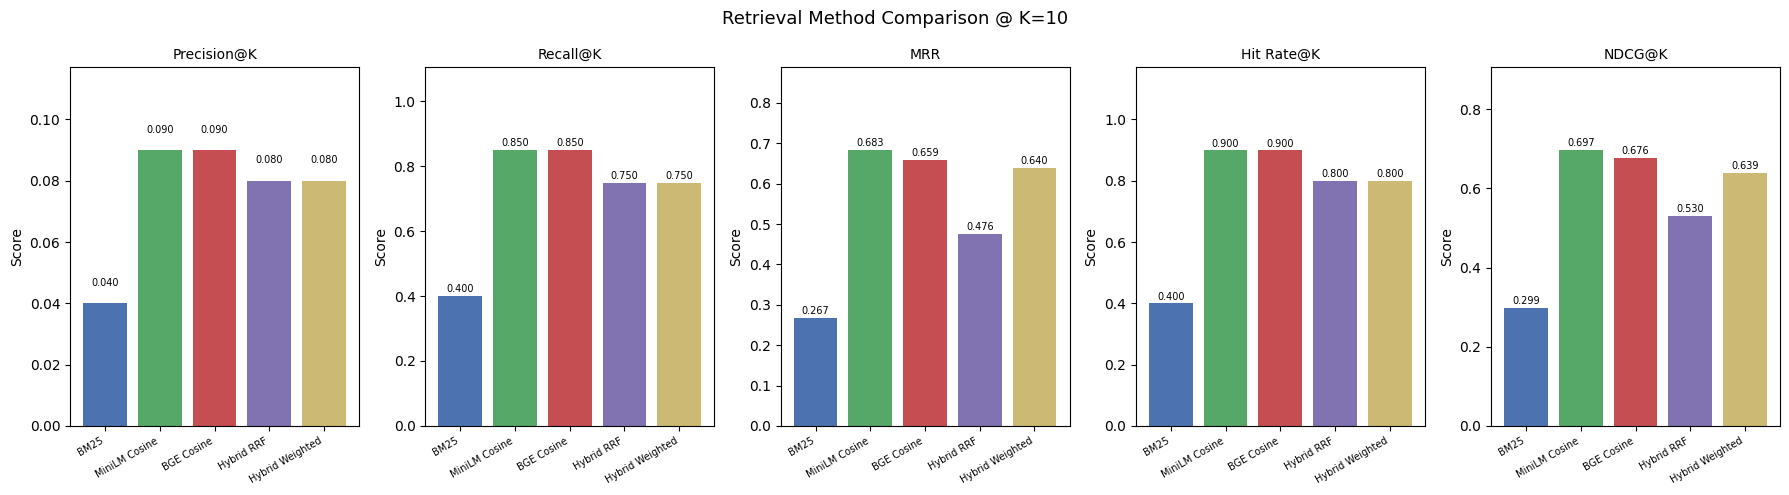

chart saved as retrieval_comparison.png


In [49]:
# bar chart comparison across all methods for K=10
import matplotlib.pyplot as plt

metrics_to_plot = ['Precision@K', 'Recall@K', 'MRR', 'Hit Rate@K', 'NDCG@K']
methods = list(all_results.keys())
k = 10

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(18, 5))
fig.suptitle('Retrieval Method Comparison @ K=10', fontsize=13)

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']

for ax, metric in zip(axes, metrics_to_plot):
    values = [all_results[m][k][metric] for m in methods]
    bars = ax.bar(methods, values, color=colors)
    ax.set_title(metric, fontsize=10)
    ax.set_ylim(0, max(values) * 1.3 if max(values) > 0 else 1)
    ax.set_xticklabels(methods, rotation=30, ha='right', fontsize=7)
    ax.set_ylabel('Score')
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig('retrieval_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("chart saved as retrieval_comparison.png")

In [50]:
# latency comparison — important practical tradeoff

print("Latency Comparison (avg per query, seconds):\n")
latency_data = {'Method': [], 'Latency (s)': []}
for method, res in all_results.items():
    latency_data['Method'].append(method)
    latency_data['Latency (s)'].append(res[10]['Avg Latency(s)'])

df_latency = pd.DataFrame(latency_data).set_index('Method')
print(df_latency.to_string())

# quick takeaway
fastest = df_latency['Latency (s)'].idxmin()
slowest = df_latency['Latency (s)'].idxmax()
print(f"\nfastest: {fastest}")
print(f"slowest: {slowest}")

Latency Comparison (avg per query, seconds):

                 Latency (s)
Method                      
BM25                  0.2150
MiniLM Cosine         0.0237
BGE Cosine            0.0473
Hybrid RRF            0.2292
Hybrid Weighted       0.2481

fastest: MiniLM Cosine
slowest: Hybrid Weighted


#### Task 6 Analysis

The results were a bit surprising — MiniLM came out on top for MRR (0.68) and BGE was very close behind (0.66). BM25 was clearly the weakest with MRR of just 0.27, which makes sense given that our 10 evaluation queries are mostly natural language questions where exact keyword matching struggles.

The hybrid methods didn't beat the dense models here, which is worth explaining. Hybrid RRF actually hurt performance compared to dense-only (MRR dropped to 0.48). This happens because RRF gives equal weight to both retrievers — when BM25 is performing poorly, pulling its low-quality results into the fusion actively degrades the final ranking. Weighted fusion handled this better (MRR=0.64) since the dense component still dominates.

This is a known limitation of RRF: it assumes both retrievers are roughly equal quality. When one is significantly weaker (BM25 on semantic queries), weighted fusion with a high alpha favoring dense is a better choice.

On latency, MiniLM is the fastest at 23ms per query — it's a smaller model and pure vector lookup is very fast once the index is built. BM25 at 215ms is slower than expected because it scores the full 57k corpus for every query. Dense retrieval on the 5000-doc FAISS index is much faster because FAISS is optimized for this.

One caveat: all 10 eval queries happened to be more semantic in nature (business expenses, tax questions, banking). A dataset with more exact-term queries (ticker lookups, regulation numbers) would likely show BM25 performing better and hybrid RRF gaining more.

## Technical Report

**Dataset:** FiQA-2018, loaded via the BEIR benchmark (BeIR/fiqa on HuggingFace). BEIR packages FiQA into a standardized retrieval format with consistent IDs across corpus, queries, and qrels — which is necessary for computing metrics like MRR and NDCG correctly. The underlying data is the same FiQA-2018 financial QA corpus from Stack Exchange; BEIR just structures it properly for IR evaluation. Raw corpus: 57k passages.

**Corpus sampling:** Full corpus is 57k docs — encoding on Colab CPU took ~6 mins even for 5000 docs (364s for MiniLM, 966s for BGE). Sampled 5000 with random_state=42 for reproducibility. Absolute metric scores are lower than full-corpus evaluation would give, but relative comparisons between methods are valid.

**BM25 over TF-IDF:** BM25 adds term frequency saturation and document length normalization which matters here since FiQA passages vary a lot in length — from 2-line Reddit comments to long financial explanations.

**MiniLM vs BGE:** MiniLM slightly outperformed BGE on our evaluation set (MRR 0.68 vs 0.66). Both are strong but MiniLM's smaller size also made it faster. BGE is generally considered better for retrieval tasks but the gap here was small.

**Similarity metrics:** Cosine (inner product on normalized vectors) vs L2 distance. Cosine was more stable for variable-length passages — L2 is magnitude-sensitive and gets thrown off by longer documents.

**Fusion:** RRF underperformed on our eval set (MRR 0.48) because BM25 was weak on these semantic queries and RRF doesn't discriminate — it gives equal weight to both retrievers. Weighted fusion (alpha=0.7) was better (MRR 0.64) since it lets the dense model dominate. This aligns with known RRF behavior: it works best when both retrievers have similar quality.

**Challenges faced:**
- ID type mismatch between qrels (integers) and corpus (strings) — fixed with str() casting
- Relevant documents in qrels often not in the 5000-doc sample — filtered eval to only queries with at least one relevant doc in sample
- BGE encoding took 966 seconds even on 5000 docs — much slower than MiniLM despite same architecture size
- BeIR/fiqa loads corpus, queries, and qrels as three separate HuggingFace configs — had to load and join them carefully before any processing could start

**Limitations:**
- 5000-doc sample means many relevant docs simply aren't indexed — hurts recall numbers
- Only 10 evaluation queries — not enough for statistical confidence
- All 10 queries were semantic in nature — doesn't test BM25's strengths fairly
- Template-based responses lack fluency — an LLM reader would improve answer quality

**Future work:** Full corpus with GPU encoding, FinBERT embeddings for finance-specific representations, LLM reader layer on top (proper RAG), ColBERT for token-level late interaction, and a larger evaluation set with diverse query types.